In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = "../../data/"

target = pd.read_csv(data_dir + "train.csv")

book = pd.read_parquet(data_dir + "book_train.parquet")
trade = pd.read_parquet(data_dir + "trade_train.parquet")

In [ ]:

# 两档总挂单量。注意：算 WAP1 不用这个，用的是一档的买卖量之和
book["tot_size"] = book["bid_size1"] + book["bid_size2"] + book["ask_size1"] + book["ask_size2"]

# WAP（加权中间价）：买价乘卖量，卖价乘买量，权重是交叉的
# 卖单多，说明价格更可能往下走，所以 WAP 更靠近买价；买单多则更靠近卖价
book["wap1"] = ((book["bid_price1"] * book["ask_size1"] + book["ask_price1"] * book["bid_size1"])
             / (book["bid_size1"] + book["ask_size1"])).astype("float32")

book["wap2"] = ((book["bid_price2"] * book["ask_size2"] + book["ask_price2"] * book["bid_size2"])
             / (book["bid_size2"] + book["ask_size2"])).astype("float32")

book["wap12"] = ((book["bid_price1"] * book["ask_size1"] + book["ask_price1"] * book["bid_size1"] + 
            book["bid_price2"] * book["ask_size2"] + book["ask_price2"] * book["bid_size2"])
             / book["tot_size"]).astype("float32")

for k in ["1", "2", "12"]:
    book[f"log_wap{k}"] = np.log(book[f"wap{k}"])

log_cols = ["log_wap1", "log_wap2", "log_wap12"]
ret_cols = ["log_ret1", "log_ret2", "log_ret12"]

book[ret_cols] = book.groupby(["stock_id", "time_id"], observed=True)[log_cols].diff().to_numpy()


In [12]:
def realized_vol(series):
    return np.sqrt(np.sum(np.square(series)))

rv = book.groupby(by = ["stock_id", "time_id"], observed=True)[["log_ret1", "log_ret2", "log_ret12"]].agg(realized_vol).reset_index()

rv.rename(columns={"log_ret1":"rv1", "log_ret2":"rv2", "log_ret12":"rv12"}, inplace=True)

rv

,stock_id,time_id,rv1,rv2,rv12
0,0,5,0.004499,0.006999,0.004106
1,0,11,0.001204,0.002476,0.001507
2,0,16,0.002369,0.004801,0.002469
3,0,31,0.002574,0.003637,0.002709
4,0,62,0.001895,0.003257,0.001932
...,...,...,...,...,...
428927,99,32751,0.001436,0.001835,0.001581
428928,99,32753,0.001795,0.001960,0.001811
428929,99,32758,0.001658,0.001981,0.001670
428930,99,32763,0.002213,0.003033,0.002272


In [13]:
combined = pd.merge(target, rv, how = "outer", on = ["stock_id", "time_id"])
combined.isna().any()


stock_id    False
time_id     False
target      False
rv1         False
rv2         False
rv12        False
dtype: bool

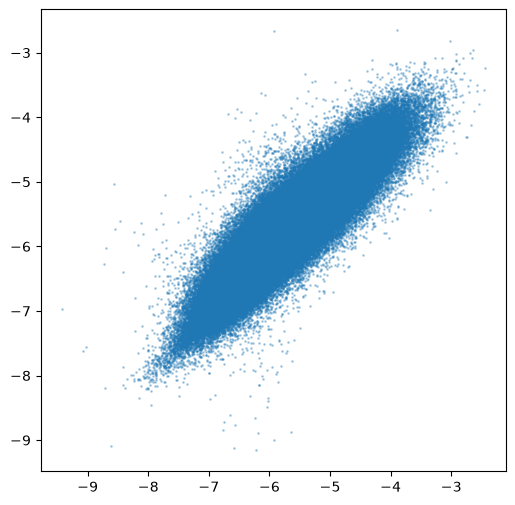

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(np.log(combined["rv1"]), np.log(combined["target"]), s=1, alpha=0.3)
plt.show()

In [18]:
def rmspe(y_true, y_pred):
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2))

# baseline：直接用当前窗口的 RV 预测 target
rmspe(combined["target"], combined["rv1"])


0.34135441481106876

In [19]:
cols = ["rv1", "rv2", "rv12", "target"]

print("Pearson（原始值）")
print(combined[cols].corr()["target"])

print("Pearson（取 log 后）")
print(np.log(combined[cols]).corr()["target"])

print("Spearman（秩相关）")
print(combined[cols].corr(method="spearman")["target"])


Pearson（原始值）
rv1       0.873777
rv2       0.863870
rv12      0.865103
target    1.000000
Name: target, dtype: float64
Pearson（取 log 后）
rv1       0.910804
rv2       0.900791
rv12      0.900584
target    1.000000
Name: target, dtype: float64
Spearman（秩相关）
rv1       0.908099
rv2       0.899633
rv12      0.897520
target    1.000000
Name: target, dtype: float64


In [20]:
# claude：减去constant c，from log to original target

# 按 time_id 切分 train / val：同一时刻的所有股票要放在同一边，避免信息泄露
rng = np.random.default_rng(0)
tids = combined["time_id"].unique()
val_tids = rng.choice(tids, size=len(tids) // 5, replace=False)
is_val = combined["time_id"].isin(val_tids).to_numpy()
is_tr = ~is_val

y = combined["target"].to_numpy()
x = combined["rv1"].to_numpy()

# 1. log-log OLS：log(target) = a + b * log(rv1)
X = np.column_stack([np.ones(len(x)), np.log(x)])
beta, *_ = np.linalg.lstsq(X[is_tr], np.log(y[is_tr]), rcond=None)
pred = np.exp(X @ beta)

# 2. 缩放系数 c：最小化训练集的 RMSPE，有解析解
c = np.sum(pred[is_tr] / y[is_tr]) / np.sum((pred[is_tr] / y[is_tr]) ** 2)

# 3. 对照：用正态假设算出的理论系数 exp(-1.5 σ²)
s2 = np.var(np.log(y[is_tr]) - np.log(pred[is_tr]))

print(f"a = {beta[0]:.4f}, b = {beta[1]:.4f}")
print(f"c = {c:.4f}, exp(-1.5σ²) = {np.exp(-1.5 * s2):.4f}")
print()
print(f"baseline (pred = rv1) : {rmspe(y[is_val], x[is_val]):.4f}")
print(f"log OLS, exp(pred)    : {rmspe(y[is_val], pred[is_val]):.4f}")
print(f"log OLS, exp(pred) * c: {rmspe(y[is_val], c * pred[is_val]):.4f}")


a = -0.8713, b = 0.8567
c = 0.8986, exp(-1.5σ²) = 0.9017

baseline (pred = rv1) : 0.3453
log OLS, exp(pred)    : 0.2897
log OLS, exp(pred) * c: 0.2669
